In [1]:
%load_ext autoreload
%autoreload 2

%matplotlib inline

import value_iteration.task.thread_the_needle as e
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from value_iteration.models import MCTS, GridWorldNode, ValueIterationNetwork
from value_iteration.models import UntiledValueIterationNetwork as ValueIterationNetwork
from value_iteration.models.utils import softmax, evaluate_policy
from tqdm import tqdm


In [2]:
# define the enviornment
n_rows, n_columns = 20, 20
movement_penalty = 0
slip_probability = 0.05
random_movement_on_error = False

transition_functions, state_reward_function, optimal_policy = e.make_thread_the_needle(
    n_rows=n_rows,
    n_columns=n_columns,
    movement_penalty=movement_penalty,
    slip_probability=slip_probability,
    random_movement_on_error=random_movement_on_error,
    sparse=False,
)


state_action_reward_functions = e.get_state_action_reward_from_sucessor_rewards(
    state_reward_function, transition_functions
)


grid_shape = (n_rows, n_columns)

goal_state = 0
bottleneck_start_state = n_rows * n_columns - n_columns // 2
corner_start_state = n_rows * n_columns - 1

Text(0.5, 1.0, 'Thread-the-needle task')

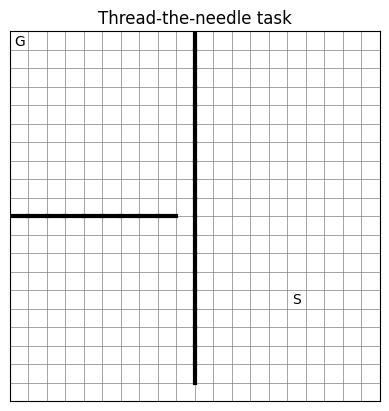

In [3]:
plt.imshow(np.zeros((n_rows, n_columns)), cmap="Greys")
e.clean_up_thread_the_needle_plot(plt.gca(), n_columns, n_rows)

plt.gca().annotate("G", (0, 0), ha="center", va="center", c="k")
plt.gca().annotate("S", (n_rows - 5, n_columns - 6), ha="center", va="center", c="k")
plt.title("Thread-the-needle task")
# plt.savefig("images/thread_the_needle_task.png", dpi=300)

# Value iteration

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/24 [00:00<?, ?it/s]

Text(0.5, 0.98, 'Policy Error')

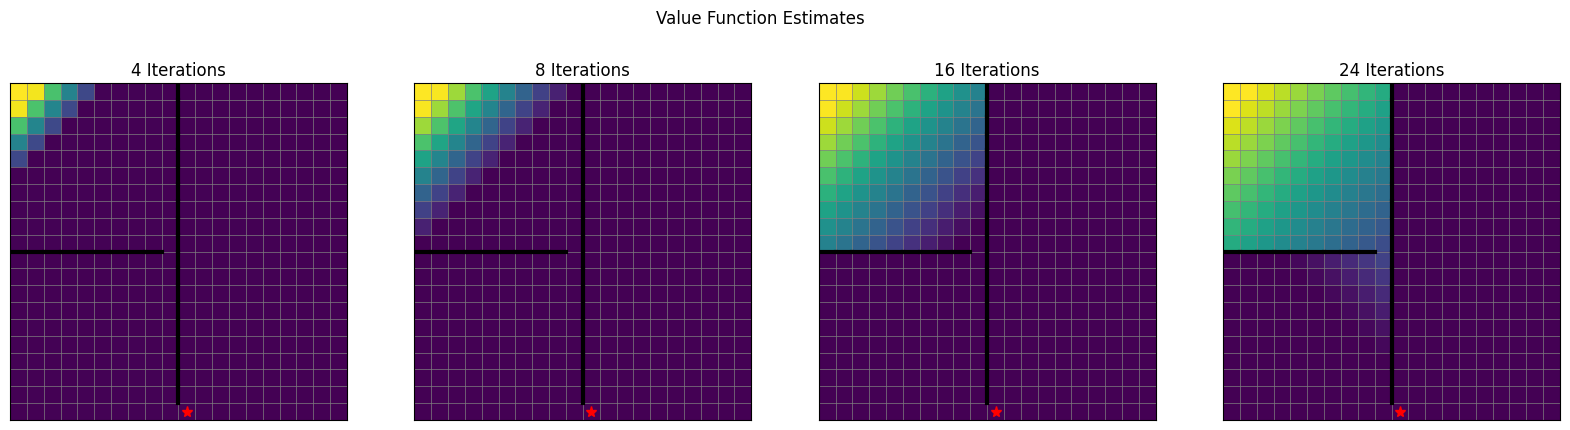

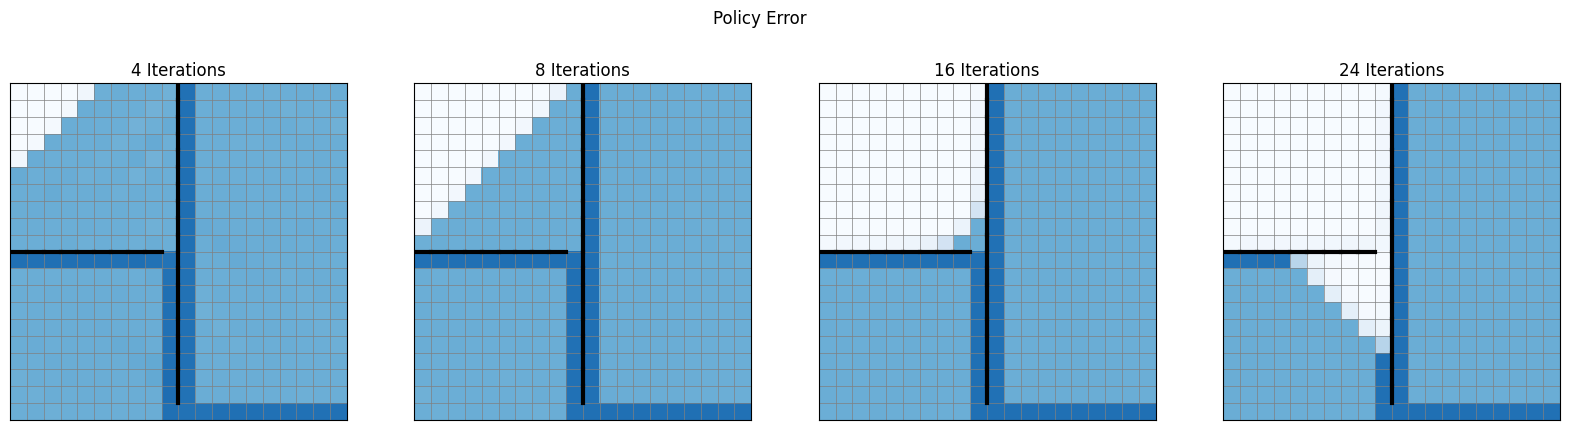

In [4]:
gamma = 0.99
beta = 5

common_model_kwargs = dict(
    transition_functions=transition_functions,
    reward_functions=state_action_reward_functions,
    n_rows=n_rows,
    n_columns=n_columns,
)


fig_v, axes_v = plt.subplots(1, 4, figsize=(20, 5))
fig_e, axes_e = plt.subplots(1, 4, figsize=(20, 5))


# 1 iteration
def evalute_plot_vi(iterations, ax_v, ax_e):
    Q, R = ValueIterationNetwork.value_iteration(
        gamma=gamma, **common_model_kwargs, iterations=iterations
    )
    pi = softmax(Q, beta=beta)
    error = evaluate_policy(
        pi, optimal_policy=optimal_policy
    )

    ax_v.imshow(R.reshape(n_rows, n_columns))

    r, c = e.GridWorld.get_position_from_state(bottleneck_start_state, n_columns)
    ax_v.plot(c, r, "*", c="r", markersize=8)
    e.clean_up_thread_the_needle_plot(ax_v, n_columns, n_rows)
    ax_v.set_title(f"{iterations} Iterations")

    pos = ax_e.imshow(
        error.reshape(grid_shape),
        cmap=sns.color_palette("Blues", as_cmap=True),
        vmin=0,
        vmax=1,
    )
    e.clean_up_thread_the_needle_plot(ax_e, n_columns, n_rows)
    ax_e.set_title(f"{iterations} Iterations")


evalute_plot_vi(4, axes_v[0], axes_e[0])
evalute_plot_vi(8, axes_v[1], axes_e[1])
evalute_plot_vi(16, axes_v[2], axes_e[2])
evalute_plot_vi(24, axes_v[3], axes_e[3])

fig_v.suptitle("Value Function Estimates")
fig_e.suptitle("Policy Error")

# fig_v.savefig("images/thread_the_needle_value_function.png", dpi=300)
# fig_e.savefig("images/thread_the_needle_policy_error.png", dpi=300)

# MCTS